# Figur 6 · Sagde partierne det samme, som de stemte? (med tjek)

**Hvilken del af spørgsmålet figuren besvarer (Q3):** Stemte partierne i 2022–26 i den retning, de talte for i valgkampen 2022, på tre emner?

- **SAGDE (x):** partiets gennemsnitlige stance i DR/TV 2-citater om emnet (−1 = imod, +1 = for).
- **GJORDE (y):** andelen af partiets stemmer på nøglelovene, der **støttede emnet**. For "bred regering": andelen af omstridte endelige afstemninger, hvor partiet stemte med regeringen.

**Tjek, der vises ved siden af påstanden (kravet i opgaven):** citaterne håndkodes af én af os. Stance-modellen sammenlignes med håndlabels → modellens træfsikkerhed og κ mod en flertalsklasse-baseline (altid at gætte den hyppigste klasse). Figurens punkter bruger håndlabels.

Tallene skrives direkte i figuren og i captionen, som laves automatisk nederst.

In [9]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import cohen_kappa_score

# Find repoets data-mappe uanset hvor notebooken ligger (ingen absolutte stier)
MAPPE = next(p / "data" for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed" / "stemmer_2022_2026.csv").exists())
PARTIER = ["S", "V", "M", "SF", "DD", "LA", "KF", "EL", "DF", "RV", "ALT"]
REGERING = {"S", "V", "M"}
OPPOSITION = [p for p in PARTIER if p not in REGERING]
FARVER = {"S": "#E32F3B", "V": "#254264", "M": "#B48CD2", "SF": "#E07EA8", "DD": "#7896D2",
          "LA": "#3FB2BE", "KF": "#5C8A3A", "EL": "#E6801A", "DF": "#EAC73E", "RV": "#733280", "ALT": "#2B8738"}
EMNER = ["Skattelettelser", "CO2-afgift / grøn omstilling", "Bred regering"]
EMNE_EN = {"Skattelettelser": "Tax cuts", "CO2-afgift / grøn omstilling": "CO2 tax / green transition",
           "Bred regering": "Broad government"}
MIN_CITATER = 3                      # mindst 3 citater pr. parti og emne
STANCE_GRAENSE, STEMME_GRAENSE = 0.15, 0.10   # |stance| > 0,15 og |gjorde − 0,5| >= 0,10 tæller som klar
VAERDI = {"for": 1, "neutral": 0, "imod": -1}
MAPPE = Path(MAPPE)                      # tåler også MAPPE = "../data/" som tekst
print("Data:", MAPPE)

Data: /Users/salmahirsi/Documents/GitHub/Politics-Network/data


## 1 · SAGDE: stance-modellen (altid indlæst, så den kan valideres)

Samme relevansfilter som før: citatet skal ligge i emnets LDA-emne **og** nævne et emneord.

In [10]:
LDA_FILTER = {"Skattelettelser": ("Blokpolitik & Statsfinanser",
                                  r"skat|topskat|økonomi|milliard|inflation|finans|budget|blå blok|rød blok|borgerlig"),
              "CO2-afgift / grøn omstilling": ("Økonomi & Landbrug",
                                  r"co2|landbrug|klima|grøn|afgift|landmænd|natur|miljø"),
              "Bred regering": ("Regeringsdannelse & Midten",
                                  r"regering|midten|samarbejd|bred|statsminister|blok|flertal|moderaterne|dronningerunde|mandat")}
q = pd.read_csv(MAPPE / "lda_stance_results.csv", encoding="utf-8-sig")
q = q[q["parti"].isin(PARTIER)]
dele = []
for emne, (lda_emne, regex) in LDA_FILTER.items():
    d = q[(q["lda_emne"] == lda_emne) & q["citat"].str.lower().str.contains(regex)].copy()
    d["emne"] = emne
    dele.append(d)
model = pd.concat(dele)
model["model_stance"] = model["stance_label"].str.lower()
model = model[["emne", "parti", "politiker", "citat", "model_stance"]]
print(len(model), "relevante citater med model-stance")

115 relevante citater med model-stance


## 2 · Tjek: håndkodning og validering af modellen

Læg `emnecitater_kodeark.csv` i `data/`, udfyldt af én person (`relevant` = ja/nej; `kodning` = for / imod / neutral). Kolonnerækkefølgen skal være som i arket.

- **Håndlabels** er guld-standarden. Modellen sammenlignes med dem.
- **Baseline** = altid at gætte den hyppigste klasse. Modellen skal slå den for at være brugbar.

Findes arket ikke, bruges modellen, og figuren markeres tydeligt som *ikke valideret*.

In [11]:
kodeark = "/Users/salmahirsi/Documents/GitHub/Politics-Network/data/emnecitater1.csv"
TJEK = {}                                # alt, der skal stå i figuren og captionen

def laes_kodeark(sti):
    # Læser arket robust: ; eller , som separator, utf-8 eller Excel-tegnsæt, én eller to kodningskolonner.
    for enc in ["utf-8-sig", "cp1252", "latin-1"]:
        try:
            linjer = Path(sti).read_text(encoding=enc).splitlines()
            break
        except UnicodeDecodeError:
            continue
    # spring evt. titellinjer over: header-linjen er den første, der indeholder både 'citat' og 'emne'
    header = next(i for i, l in enumerate(linjer) if ("citat" in l.lower().replace("emnecitater", "")) and (";" in l or "," in l) and "relevant" in l.lower())
    if header:
        print(f"OBS: springer {header} linje(r) over før kolonnenavnene: {linjer[:header]}")
    sep = ";" if linjer[header].count(";") >= linjer[header].count(",") else ","
    ark = pd.read_csv(sti, sep=sep, encoding=enc, dtype=str, skiprows=header)
    ark.columns = [str(c).strip().lower() for c in ark.columns]
    # find kodningskolonnen: 'kodning', 'kodning_1' eller 'k1' (den første, der har indhold)
    kandidater = [c for c in ["kodning", "kodning_1", "kodning1", "k1", "stance_hand"] if c in ark.columns]
    kandidater = [c for c in kandidater if ark[c].notna().any()]
    if not kandidater or "citat" not in ark.columns or "emne" not in ark.columns:
        raise ValueError(f"Kan ikke finde kolonnerne emne, citat og kodning i arket. Fundne kolonner: {list(ark.columns)}")
    ark["kodning"] = ark[kandidater[0]]
    if "relevant" not in ark.columns:
        ark["relevant"] = "ja"
    rens = lambda x: x.fillna("").astype(str).str.strip().str.lower()
    ark["kodning"] = rens(ark["kodning"]).replace({"+1": "for", "1": "for", "-1": "imod", "0": "neutral",
                                                      "mod": "imod", "against": "imod", "neutralt": "neutral"})
    ark["relevant"] = rens(ark["relevant"]).replace({"j": "ja", "yes": "ja", "n": "nej", "no": "nej"})
    for c in ["emne", "citat", "parti", "politiker"]:
        if c in ark.columns:
            ark[c] = ark[c].astype(str).str.strip()
    return ark

kodeark = Path(kodeark)                  # virker også, hvis stien er skrevet som tekst
if kodeark.exists():
    ark = laes_kodeark(kodeark)
    ukodet = ark[(ark["relevant"] != "nej") & ~ark["kodning"].isin(VAERDI)]
    if len(ukodet):
        print(f"OBS: {len(ukodet)} citater er ikke kodet (eller har en ukendt værdi) og springes over. Værdier:",
              ukodet["kodning"].value_counts().to_dict())
    TJEK["irrelevante"] = int((ark["relevant"] == "nej").sum())
    ark = ark[(ark["relevant"] != "nej") & ark["kodning"].isin(VAERDI)]

if kodeark.exists() and len(ark):
    KILDE = "hand-coded"
    TJEK["n_kodet"] = len(ark)
    guld = ark.copy()
    guld["stance"] = guld["kodning"]
    # modellen mod håndlabels (matches på emne + citattekst)
    mm = model[["emne", "citat", "model_stance"]].drop_duplicates(["emne", "citat"]).copy()
    mm["citat"] = mm["citat"].astype(str).str.strip()
    m = guld.merge(mm, on=["emne", "citat"], how="inner")
    TJEK["n_guld"] = len(m)
    if len(m) < len(guld):
        print(f"OBS: {len(guld) - len(m)} håndkodede citater kunne ikke matches med modellens citater.")
    TJEK["model_acc"] = (m["model_stance"] == m["stance"]).mean()
    TJEK["model_kappa"] = cohen_kappa_score(m["stance"], m["model_stance"])
    TJEK["baseline_acc"] = m["stance"].value_counts(normalize=True).max()
    print(f"Håndkodet: {TJEK['n_kodet']} citater; {TJEK['irrelevante']} markeret irrelevante")
    print("Fordeling af dine koder:", guld["stance"].value_counts().to_dict())
    print(f"Model mod håndlabels ({TJEK['n_guld']} citater): {TJEK['model_acc']:.0%} rigtige (κ = {TJEK['model_kappa']:.2f}), "
          f"baseline {TJEK['baseline_acc']:.0%}")
    print(pd.crosstab(m["stance"], m["model_stance"], rownames=["hånd"], colnames=["model"]))
    citater = guld[["emne", "parti", "politiker", "stance", "citat"]].copy()
else:
    KILDE = "stance model (NOT validated)"
    print("Kodearket mangler eller er tomt: bruger stance-modellen. Figuren markeres som ikke valideret.")
    citater = model.rename(columns={"model_stance": "stance"})[["emne", "parti", "politiker", "stance", "citat"]].copy()

citater["v"] = citater["stance"].map(VAERDI)
sagde = citater.groupby(["emne", "parti"])["v"].agg(stance="mean", n="size").reset_index()
sagde = sagde[sagde["n"] >= MIN_CITATER].reset_index(drop=True)
sagde.round(2)

OBS: 35 citater er ikke kodet (eller har en ukendt værdi) og springes over. Værdier: {'': 33, 'nej': 2}
OBS: 1 håndkodede citater kunne ikke matches med modellens citater.
Håndkodet: 66 citater; 38 markeret irrelevante
Fordeling af dine koder: {'for': 48, 'imod': 13, 'neutral': 5}
Model mod håndlabels (65 citater): 69% rigtige (κ = 0.38), baseline 72%
model    for  imod  neutral
hånd                       
for       35    12        0
imod       2    10        1
neutral    1     4        0


,emne,parti,stance,n
0,Bred regering,DD,-1.00,3
1,Bred regering,EL,-0.67,3
2,Bred regering,LA,-0.33,3
3,Bred regering,M,0.67,6
4,Bred regering,S,0.87,30
5,CO2-afgift / grøn omstilling,EL,0.33,3
6,CO2-afgift / grøn omstilling,SF,0.78,9
7,CO2-afgift / grøn omstilling,V,1.00,3


## 3 · GJORDE: partiernes stemmer

Partiets position på en afstemning = flertallet blandt de medlemmer i data, der stemte for eller imod.
Bemærk: `stemmer_2022_2026.csv` indeholder kun de 62 MF'ere, der blev citeret i valgkampen.

In [12]:
st = pd.read_csv(MAPPE / "processed" / "stemmer_2022_2026.csv", usecols=["afstemning_id", "parti", "stemme"])
st = st[st["parti"].isin(PARTIER) & st["stemme"].isin(["For", "Imod"])]
position = st.groupby(["afstemning_id", "parti"])["stemme"].agg(lambda x: x.value_counts().idxmax()).unstack()

afst = pd.read_csv(MAPPE / "processed" / "afstemninger_2022_2026.csv")
endelige = afst[afst["afstemningstype"] == "Endelig vedtagelse"]
love_alle = endelige[endelige["sagstype"] == "Lovforslag"].copy()
tekst = (love_alle["titel_kort"].fillna("") + " " + love_alle["resume"].fillna("")).str.lower()

er_skat = (love_alle["emne"].isin(["Økonomi, skat & energipriser", "Sundhed & psykiatri"])
           & tekst.str.contains(r"personskat|bundskat|topskat|seniorpræmie|afskaffelse af .*afgift|skattelettelse"))
er_co2 = (love_alle["emne"].isin(["Klima, miljø & landbrug", "Økonomi, skat & energipriser"])
          & tekst.str.contains(r"co2|drivhusgas|grøn skattereform|energiafgiften på fossile"))
love = pd.concat([love_alle[er_skat].assign(emne_lov="Skattelettelser", retning=1),
                  love_alle[er_co2].assign(emne_lov="CO2-afgift / grøn omstilling", retning=1)], ignore_index=True)
love.loc[love["titel_kort"].str.lower().str.contains(r"suspension|udskydelse"), "retning"] = -1   # fx L 64 B
print(love.groupby("emne_lov").size().to_string())

def gjorde_lov(emne, parti):
    # Andel af partiets stemmer på emnets love, der støttede emnet (for en lov der fremmer det, imod en der udskyder det)
    d = love[love["emne_lov"] == emne]
    d = d[d["afstemning_id"].isin(position.index)]
    s = position.loc[d["afstemning_id"], parti]
    ok = s.notna().values
    if ok.sum() == 0:
        return np.nan, 0
    i_retning = (np.where(s.values[ok] == "For", 1, -1) * d["retning"].values[ok]) == 1
    return i_retning.mean(), int(ok.sum())

# Omstridte afstemninger: endelige vedtagelser, hvor mindst tre oppositionspartier stod et andet sted end regeringen
pe = position.loc[position.index.intersection(endelige["afstemning_id"])]
reg = pe[list(REGERING)].mode(axis=1)[0]
omstridt = (pe[OPPOSITION].ne(reg, axis=0) & pe[OPPOSITION].notna()).sum(axis=1) >= 3
pe, reg = pe[omstridt], reg[omstridt]
print(len(pe), "omstridte afstemninger")

def gjorde_regering(parti):
    har = pe[parti].notna()
    return (pe.loc[har, parti] == reg[har]).mean(), int(har.sum())

gj = [gjorde_regering(p) if e == "Bred regering" else gjorde_lov(e, p) for e, p in zip(sagde["emne"], sagde["parti"])]
sagde["gjorde"], sagde["n_stemmer"] = [g[0] for g in gj], [g[1] for g in gj]
res = sagde.dropna(subset=["gjorde"]).copy()

def dom(stance, gjorde):
    klar = (np.abs(stance) > STANCE_GRAENSE) & (np.abs(gjorde - 0.5) >= STEMME_GRAENSE)
    enig = np.sign(stance) == np.sign(gjorde - 0.5)
    return np.where(~klar, "uklart", np.where(enig, "alignment", "divergens"))

res["dom"] = dom(res["stance"].values, res["gjorde"].values)
print(res["dom"].value_counts().to_string())
res.round(2)

emne_lov
CO2-afgift / grøn omstilling    29
Skattelettelser                  9
238 omstridte afstemninger
dom
alignment    6
uklart       2


,emne,parti,stance,n,gjorde,n_stemmer,dom
0,Bred regering,DD,-1.00,3,0.45,230,uklart
1,Bred regering,EL,-0.67,3,0.29,233,alignment
2,Bred regering,LA,-0.33,3,0.49,156,uklart
3,Bred regering,M,0.67,6,1.00,230,alignment
4,Bred regering,S,0.87,30,1.00,238,alignment
5,CO2-afgift / grøn omstilling,EL,0.33,3,0.92,24,alignment
6,CO2-afgift / grøn omstilling,SF,0.78,9,1.00,23,alignment
7,CO2-afgift / grøn omstilling,V,1.00,3,1.00,25,alignment


In [13]:
TJEK["n_align"] = int((res["dom"] == "alignment").sum())
TJEK["n_div"] = int((res["dom"] == "divergens").sum())
TJEK["n_uklar"] = int((res["dom"] == "uklart").sum())

## 5 · Tegn figuren med tjekket i figuren

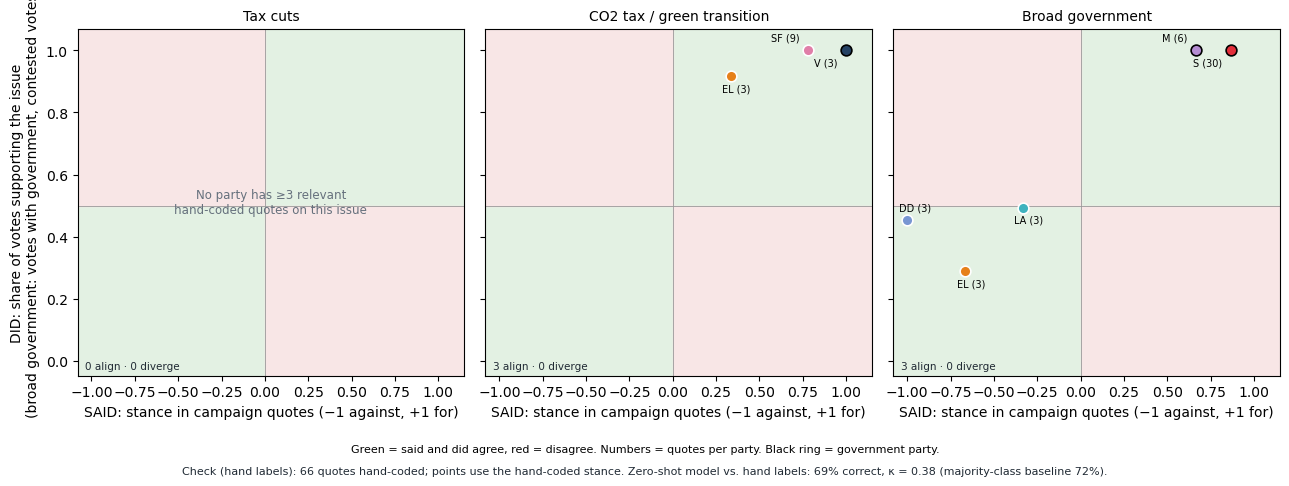

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.4), sharey=True)
for ax, emne in zip(axes, EMNER):
    for x0, y0, w, h, farve in [(0, 0.5, 1.15, 0.57, "#e3f1e3"), (-1.08, -0.05, 1.08, 0.55, "#e3f1e3"),
                                (-1.08, 0.5, 1.08, 0.57, "#f8e6e6"), (0, -0.05, 1.15, 0.55, "#f8e6e6")]:
        ax.add_patch(plt.Rectangle((x0, y0), w, h, color=farve, zorder=0))
    ax.axhline(0.5, color="#999", lw=0.6); ax.axvline(0, color="#999", lw=0.6)
    d = res[res["emne"] == emne].sort_values(["gjorde", "stance"])
    if d.empty:
        ax.text(0.5, 0.5, f"No party has ≥{MIN_CITATER} relevant\nhand-coded quotes on this issue",
                transform=ax.transAxes, ha="center", va="center", fontsize=8.5, color="#66717d")
    for k, (_, r) in enumerate(d.iterrows()):
        ax.scatter(r["stance"], r["gjorde"], s=60, color=FARVER[r["parti"]],
                   edgecolor="k" if r["parti"] in REGERING else "white", lw=1.2, zorder=3)
        # skift etiketten op/ned, så punkter oven i hinanden kan læses
        ax.annotate(f"{r['parti']} ({r['n']})", (r["stance"], r["gjorde"]), xytext=(-6, 7 if k % 2 else -11),
                    textcoords="offset points", fontsize=7, ha="right" if r["stance"] > 0.6 else "left")
    a, dv = (d["dom"] == "alignment").sum(), (d["dom"] == "divergens").sum()
    ax.text(0.02, 0.02, f"{a} align · {dv} diverge", transform=ax.transAxes, fontsize=7.5, color="#1f2933")
    ax.set_xlim(-1.08, 1.15); ax.set_ylim(-0.05, 1.07)
    ax.set_title(EMNE_EN[emne], fontsize=10)
    ax.set_xlabel("SAID: stance in campaign quotes (−1 against, +1 for)")
axes[0].set_ylabel("DID: share of votes supporting the issue\n(broad government: votes with government, contested votes)")

if "model_acc" in TJEK:
    linje1 = (f"Check (hand labels): {TJEK['n_kodet']} quotes hand-coded; points use the hand-coded stance. "
              f"Zero-shot model vs. hand labels: {TJEK['model_acc']:.0%} correct, κ = {TJEK['model_kappa']:.2f} "
              f"(majority-class baseline {TJEK['baseline_acc']:.0%}).")
else:
    linje1 = "Check (hand labels): NOT DONE. Points use the unvalidated zero-shot stance model."
fig.text(0.5, -0.04, "Green = said and did agree, red = disagree. Numbers = quotes per party. Black ring = government party.",
         ha="center", fontsize=8)
fig.text(0.5, -0.09, linje1, ha="center", fontsize=8, color="#1f2933")
plt.tight_layout()
fig.savefig("fig5_pr_emne.pdf", bbox_inches="tight")
fig.savefig("fig5_pr_emne.png", dpi=300, bbox_inches="tight")
plt.show()

In [17]:
from sklearn.metrics import classification_report

if "model_acc" in TJEK:
    print(sorted(m["model_stance"].unique()))       # tjek at modellen bruger for/imod/neutral
    KLASSER = ["for", "imod", "neutral"]

    # Precision og recall pr. klasse (alle emner samlet)
    print(classification_report(m["stance"], m["model_stance"], labels=KLASSER, zero_division=0))

    # Pr. emne (n er lille, så læs med forsigtighed)
    for emne, d in m.groupby("emne"):
        print(f"\n=== {emne} (n = {len(d)})")
        print(classification_report(d["stance"], d["model_stance"], labels=KLASSER, zero_division=0))

    # Gem tallene til figuren og captionen
    rap = classification_report(m["stance"], m["model_stance"], labels=KLASSER, zero_division=0, output_dict=True)
    for k in KLASSER:
        TJEK[f"prec_{k}"], TJEK[f"rec_{k}"], TJEK[f"n_{k}"] = rap[k]["precision"], rap[k]["recall"], int(rap[k]["support"])

    # Relevansfilteret: kun precision kan måles
    alle = laes_kodeark(kodeark)
    alle = alle[alle["relevant"].isin(["ja", "nej"])]
    TJEK["filter_prec"] = (alle["relevant"] == "ja").mean()
    print(f"\nRelevansfilter: {TJEK['filter_prec']:.0%} af {len(alle)} udvalgte citater er relevante (precision)")

['for', 'imod', 'neutral']
              precision    recall  f1-score   support

         for       0.92      0.74      0.82        47
        imod       0.38      0.77      0.51        13
     neutral       0.00      0.00      0.00         5

    accuracy                           0.69        65
   macro avg       0.44      0.50      0.45        65
weighted avg       0.74      0.69      0.70        65


=== Bred regering (n = 47)
              precision    recall  f1-score   support

         for       0.96      0.79      0.87        33
        imod       0.42      0.89      0.57         9
     neutral       0.00      0.00      0.00         5

    accuracy                           0.72        47
   macro avg       0.46      0.56      0.48        47
weighted avg       0.76      0.72      0.72        47


=== CO2-afgift / grøn omstilling (n = 16)
              precision    recall  f1-score   support

         for       0.90      0.64      0.75        14
        imod       0.17      0.

## 6 · Caption til paperet (genereres med de rigtige tal)

Captionen skal kunne læses alene: hvad er punkterne, hvad er akserne, hvad skal man se, og hvilket tjek ligger bag.

In [15]:
n_skat = int((love["emne_lov"] == "Skattelettelser").sum())
n_co2 = int((love["emne_lov"] == "CO2-afgift / grøn omstilling").sum())
if "model_acc" in TJEK:
    stance_tekst = (f"hand-coded by one author ({TJEK['n_kodet']} relevant quotes; {TJEK['irrelevante']} irrelevant or misattributed quotes removed). "
                    f"Check: the zero-shot classifier agreed with the hand labels in {TJEK['model_acc']:.0%} of quotes "
                    f"(κ = {TJEK['model_kappa']:.2f}; majority-class baseline {TJEK['baseline_acc']:.0%}).")
else:
    stance_tekst = "scored by a zero-shot NLI classifier that has NOT been validated against hand labels."
caption = (
    f"Said versus did on three issues. Each point is one party on one issue (parties with ≥{MIN_CITATER} relevant quotes). "
    f"Horizontal: mean stance of the party's DR and TV 2 campaign quotes (5 Oct–1 Nov 2022), {stance_tekst} "
    f"Vertical: share of the party's votes in 2022–26 that supported the issue ({n_skat} tax-cut bills and {n_co2} CO2/green bills, "
    f"direction reversed for bills that suspend a tax); for broad government, the share of {len(pe)} contested final votes "
    f"(≥3 opposition parties on the other side) cast with the government, which is 1 for S, V and M by construction. "
    f"Green quadrants: words and votes agree; red: they disagree. "
    f"{TJEK['n_align']} points agree, {TJEK['n_div']} disagree and {TJEK['n_uklar']} are unclear (|stance| ≤ {STANCE_GRAENSE} or vote share within ±{STEMME_GRAENSE} of 0.5)."
)
print(caption)

Said versus did on three issues. Each point is one party on one issue (parties with ≥3 relevant quotes). Horizontal: mean stance of the party's DR and TV 2 campaign quotes (5 Oct–1 Nov 2022), hand-coded by one author (66 relevant quotes; 38 irrelevant or misattributed quotes removed). Check: the zero-shot classifier agreed with the hand labels in 69% of quotes (κ = 0.38; majority-class baseline 72%). Vertical: share of the party's votes in 2022–26 that supported the issue (9 tax-cut bills and 29 CO2/green bills, direction reversed for bills that suspend a tax); for broad government, the share of 238 contested final votes (≥3 opposition parties on the other side) cast with the government, which is 1 for S, V and M by construction. Green quadrants: words and votes agree; red: they disagree. 6 points agree, 0 disagree and 2 are unclear (|stance| ≤ 0.15 or vote share within ±0.1 of 0.5).


## 7 · Citaterne bag figuren (til at læse og citere i paperet)

In [16]:
brugt = citater.merge(res[["emne", "parti"]], on=["emne", "parti"]).sort_values(["emne", "parti", "v"])
brugt.drop(columns="v").to_csv("citater_i_figur5.csv", index=False, sep=";", encoding="utf-8-sig")
print(len(brugt), "citater bag", len(res), "punkter")
for (emne, parti), d in brugt.groupby(["emne", "parti"]):
    r = res[(res["emne"] == emne) & (res["parti"] == parti)].iloc[0]
    print(f"\n=== {emne} · {parti}: stance {r['stance']:+.2f}, støttede emnet {r['gjorde']:.0%} → {r['dom']}")
    for _, c in d.iterrows():
        print(f"  [{c['stance']:>7}] {c['citat'][:200]}")

60 citater bag 8 punkter

=== Bred regering · DD: stance -1.00, støttede emnet 45% → uklart
  [   imod] Jeg vil i hvert fald sige, at jeg har meget, meget svært ved at se Barbara Bertelsen spille en særlig stor rolle, hvis der kommer en borgerlig regering.
  [   imod] Arh, jeg har godt nok svært ved at se mig selv i en regering, hvor Barbara Bertelsen sidder for bordenden, som hun gør nu, svarede Inger Støjberg.
  [   imod] Min bekymring er, at udlændingepolitikken kan ende med at blive lempet, hvis der, som nogle partier taler for, skal dannes en regering hen over midten.

=== Bred regering · EL: stance -0.67, støttede emnet 29% → alignment
  [   imod] Nej, vi kommer til at stille betingelser for at kunne pege på en regering, der betinger sig vores støtte, fastslår Peder Hvelplund.
  [   imod] Vi kan ikke støtte en regering, der vil gennemføre den plan, det må jeg bare sige direkte til dig, Mette Frederiksen.
  [neutral] Det er klart, hvis Enhedslisten skal støtte en ny regering, så k